# 04. Exploratory Data Analysis: Demographic, Socioeconomic & Anthropometric Features
**Project:** `nfhs-diabetes-ml`  
**Dataset:** `data/processed/analysis_dataset.parquet`  
**Focus:** Non-causal descriptive profiling and target-stratified comparisons across demographic, socioeconomic, and anthropometric dimensions.  


In [1]:
import sys
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

from src.config import PROJECT_ROOT, PROCESSED_DATA_DIR, FIGURES_DIR, RANDOM_STATE
from src.utils import set_seed
from src.eda import (
    load_analysis_data,
    calculate_numeric_summary,
    calculate_categorical_summary,
    generate_all_plots,
    run_full_eda
)

set_seed(RANDOM_STATE)
print(f"Project root: {PROJECT_ROOT}")


Project root: C:\Users\Lenovo\OneDrive\Desktop\ml model\nfhs-diabetes-ml


## 1. Load Cleaned Analysis Dataset

In [2]:
df = load_analysis_data()
print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Target distribution:\n{df['diabetes_status'].value_counts(normalize=True)*100}")


[2026-10-22 11:49:00] [INFO] [src.eda]: Loaded analysis dataset: 11898 rows x 59 columns


Dataset shape: 11,898 rows x 59 columns
Target distribution:
diabetes_status
0    97.755925
1     2.244075
Name: proportion, dtype: float64


## 2. Categorical Variables Summary Across Target Groups

In [3]:
cat_cols = [
    "age_group", "residence", "marital_status", "education",
    "wealth_group", "occupation", "health_insurance", "region", "bmi_category"
]
cat_summary = calculate_categorical_summary(df, cat_cols)
cat_summary.sort_values(by=["variable", "diabetic_prevalence_pct"], ascending=[True, False]).head(20)


,variable,category,count,pct_of_sample,diabetic_count,diabetic_prevalence_pct
3,age_group,45-49,1714,14.405782,83,4.842474
1,age_group,35-44,3432,28.845184,109,3.175991
0,age_group,25-34,3448,28.979660,57,1.653132
2,age_group,15-24,3304,27.769373,18,0.544794
30,bmi_category,Obese (>=30.0),2133,17.927383,110,5.157056
28,bmi_category,Overweight (25.0-29.9),5692,47.839973,119,2.090654
29,bmi_category,Normal (18.5-24.9),3571,30.013448,31,0.868104
31,bmi_category,Underweight (<18.5),132,1.109430,0,0.000000
9,education,Secondary,5607,47.125567,135,2.407705
11,education,Higher,1956,16.439738,46,2.351738


## 3. Continuous Variables Summary Across Target Groups

In [4]:
num_cols = ["age", "height_cm", "weight_kg", "bmi", "systolic_bp", "diastolic_bp"]
num_summary = calculate_numeric_summary(df, num_cols)
num_summary


,variable,group,n_valid,mean,std,median,q25,q75,min,max
0,age,Overall,11898,32.161035,10.036738,32.000,24.00,41.000,15.00,49.00
1,age,Non-Diabetic,11631,32.001977,10.021134,32.000,23.00,41.000,15.00,49.00
2,age,Diabetic,267,39.089888,8.093403,41.000,34.00,46.000,16.00,49.00
3,height_cm,Overall,11528,152.444171,6.325507,152.400,148.20,156.600,129.50,178.30
4,height_cm,Non-Diabetic,11268,152.438916,6.318161,152.400,148.20,156.600,129.50,178.30
5,height_cm,Diabetic,260,152.671923,6.644824,152.000,148.10,157.125,132.50,173.10
6,weight_kg,Overall,11528,62.035262,9.928534,61.600,55.00,68.600,27.30,107.80
7,weight_kg,Non-Diabetic,11268,61.900745,9.887299,61.500,54.90,68.400,27.30,107.80
8,weight_kg,Diabetic,260,67.865000,9.979870,67.650,60.50,75.200,44.30,101.10
9,bmi,Overall,11528,26.663110,3.616868,26.650,24.21,29.120,14.04,40.33


## 4. Generate & Display All 12 Required Figures

In [5]:
saved_plots = generate_all_plots(df)
print(f"Generated {len(saved_plots)} plots successfully.")
for p in saved_plots:
    print(f"  - {p.name}")


C:\Users\Lenovo\OneDrive\Desktop\ml model\nfhs-diabetes-ml\src\eda.py:253: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Lenovo\OneDrive\Desktop\ml model\nfhs-diabetes-ml\src\eda.py:265: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([TARGET_LABELS[0], TARGET_LABELS[1]], fontsize=11)


[2026-10-22 11:49:04] [INFO] [src.eda]: Successfully generated and saved all 12 plots to: C:\Users\Lenovo\OneDrive\Desktop\ml model\nfhs-diabetes-ml\reports\figures


Generated 12 plots successfully.
  - 01_target_class_count_plot.png
  - 02_age_histogram.png
  - 03_age_distribution_by_target.png
  - 04_bmi_histogram.png
  - 05_bmi_distribution_by_target.png
  - 06_bmi_category_distribution.png
  - 07_target_status_by_bmi_category.png
  - 08_target_status_by_residence.png
  - 09_target_status_by_education.png
  - 10_target_status_by_wealth_group.png
  - 11_target_status_by_age_group.png
  - 12_target_status_by_region.png


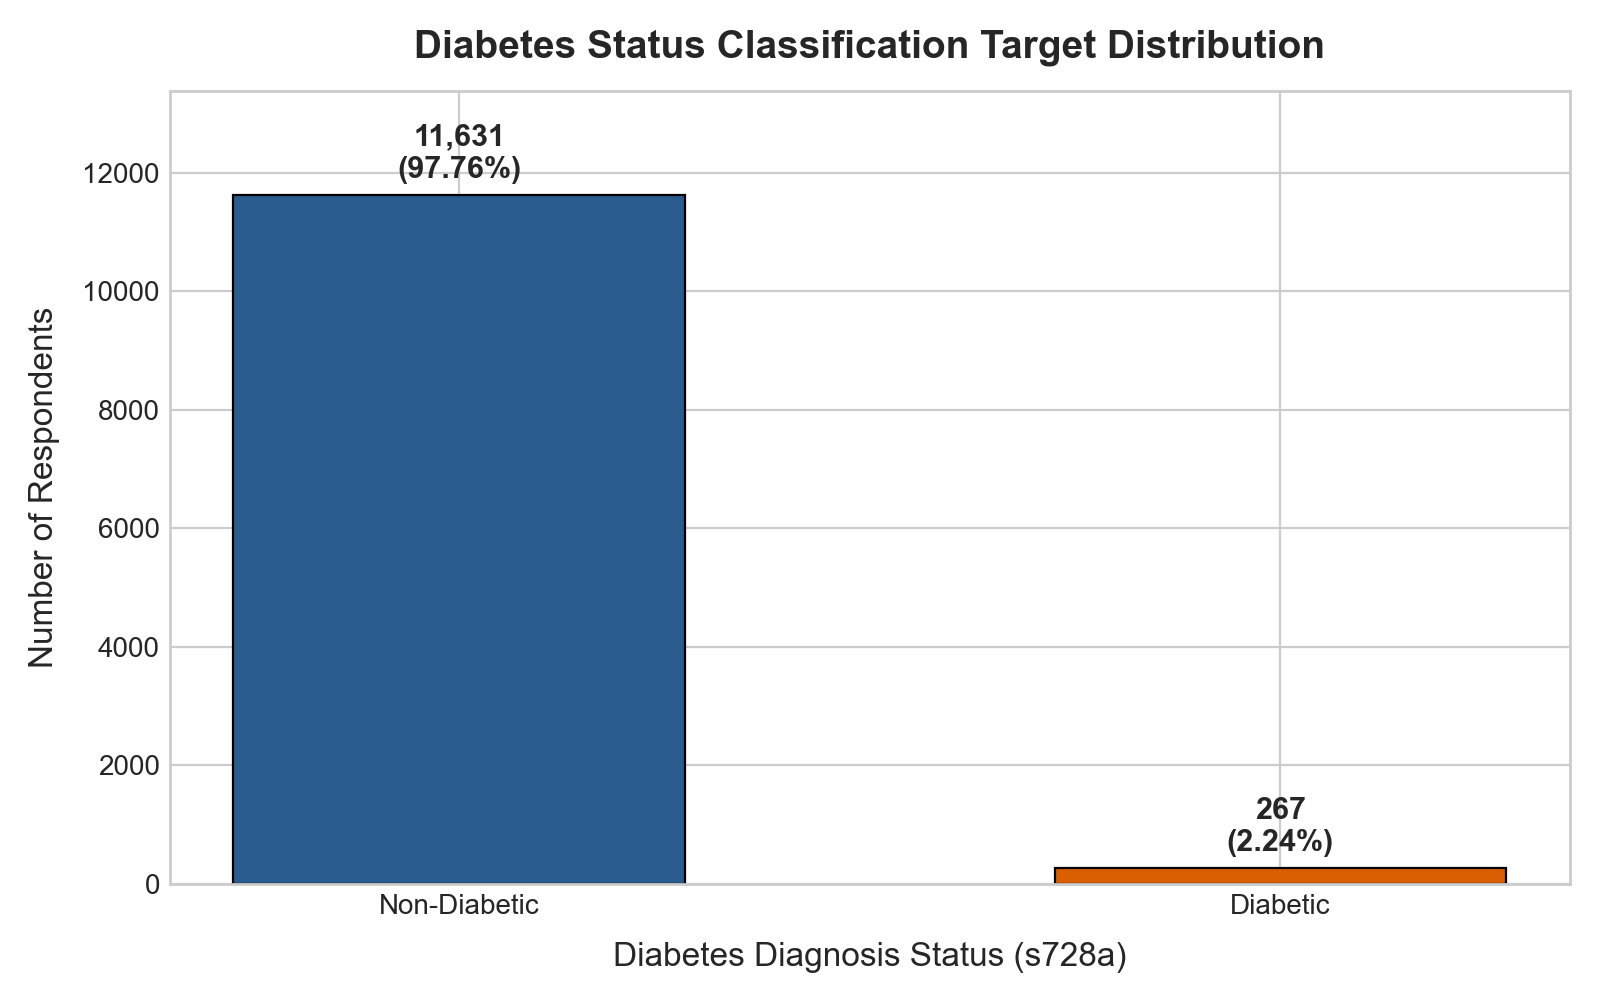

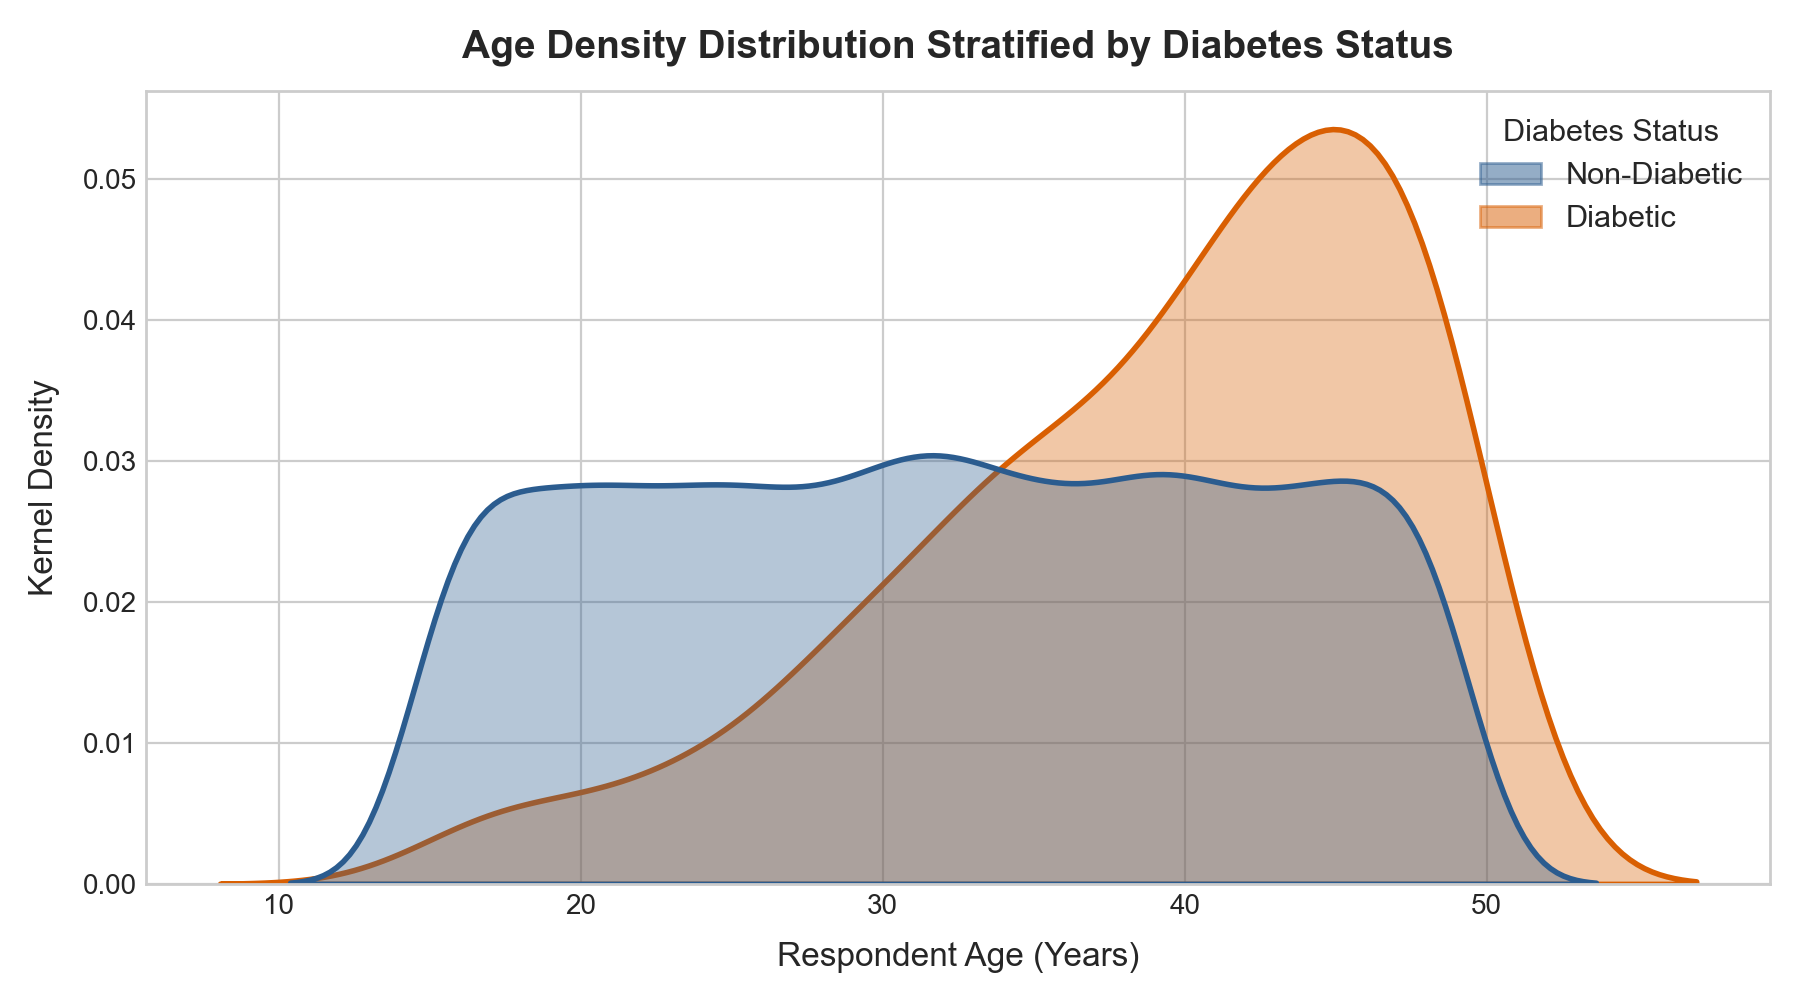

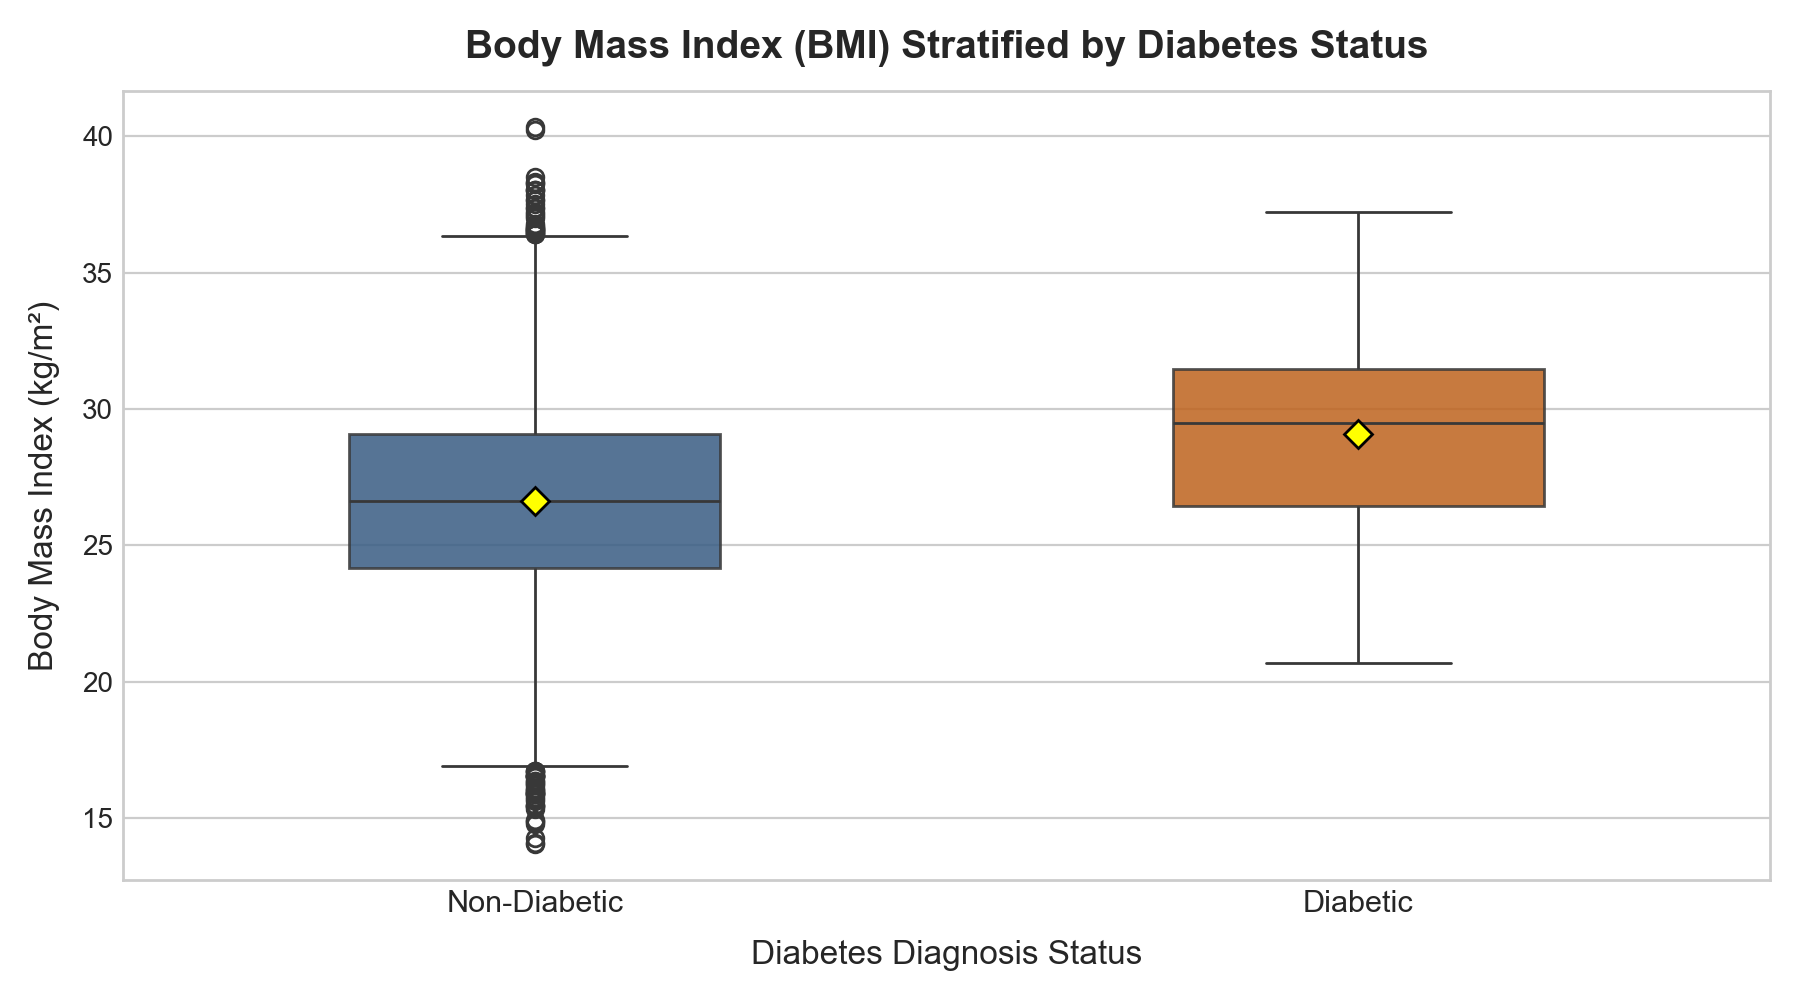

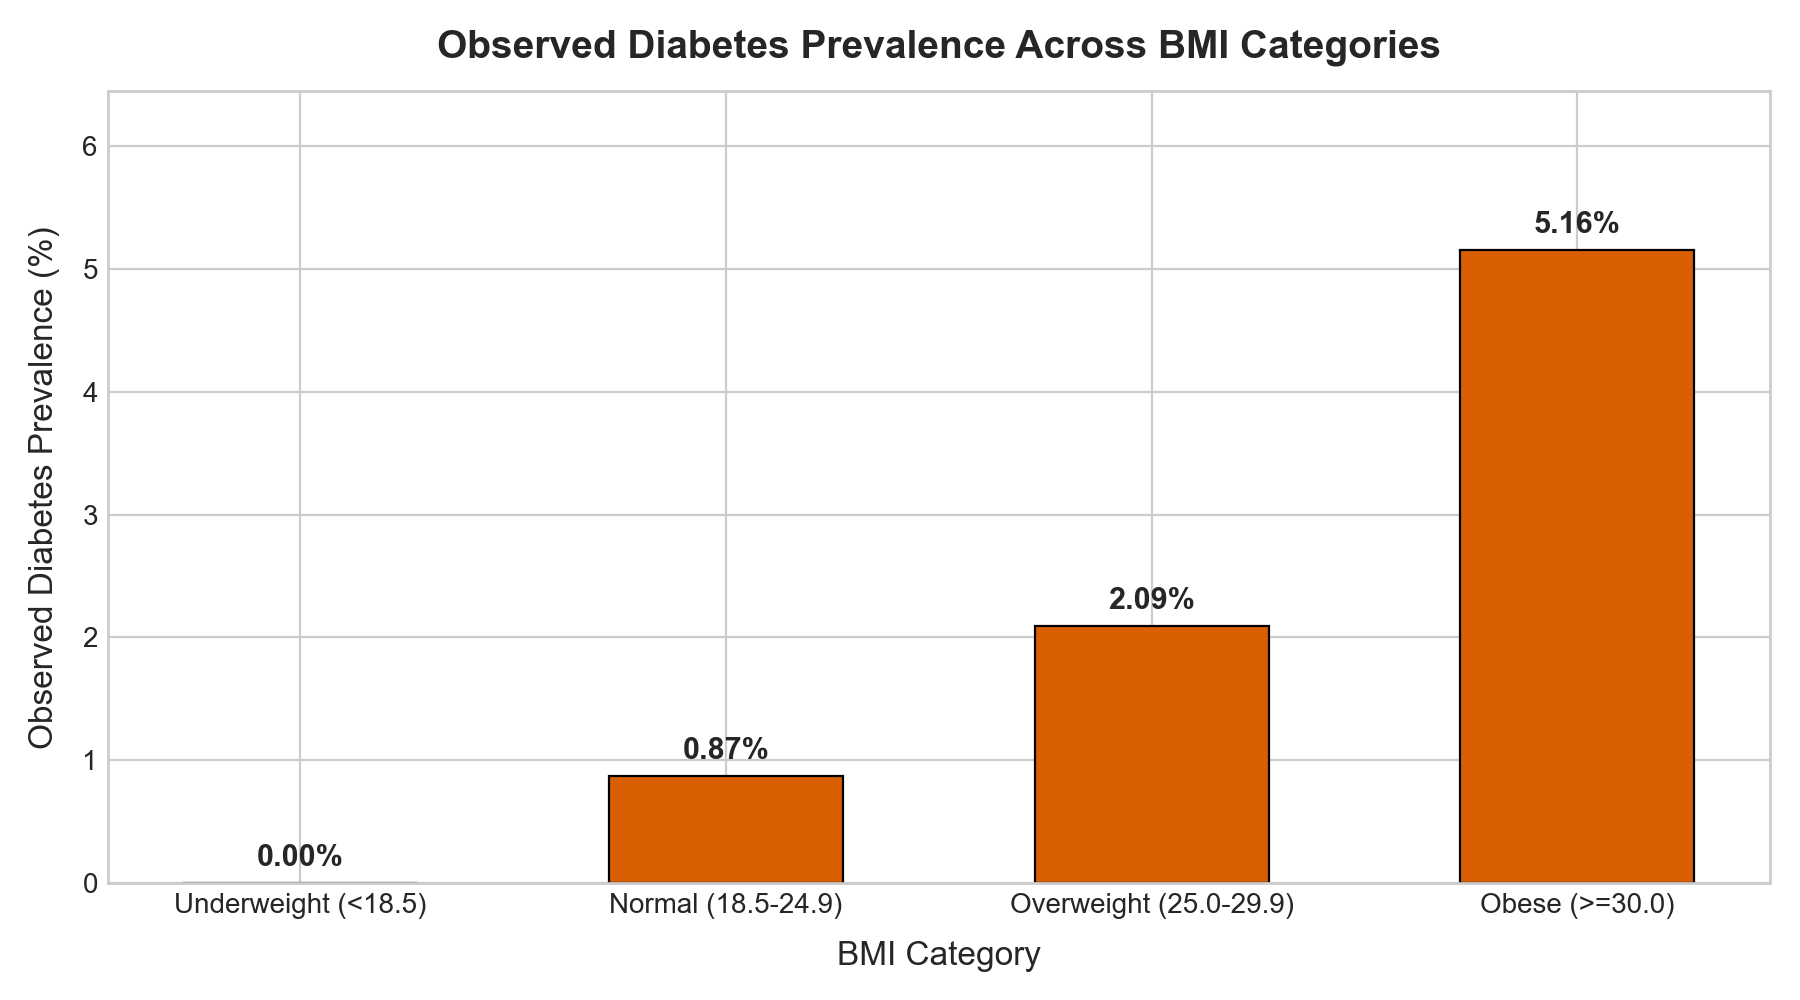

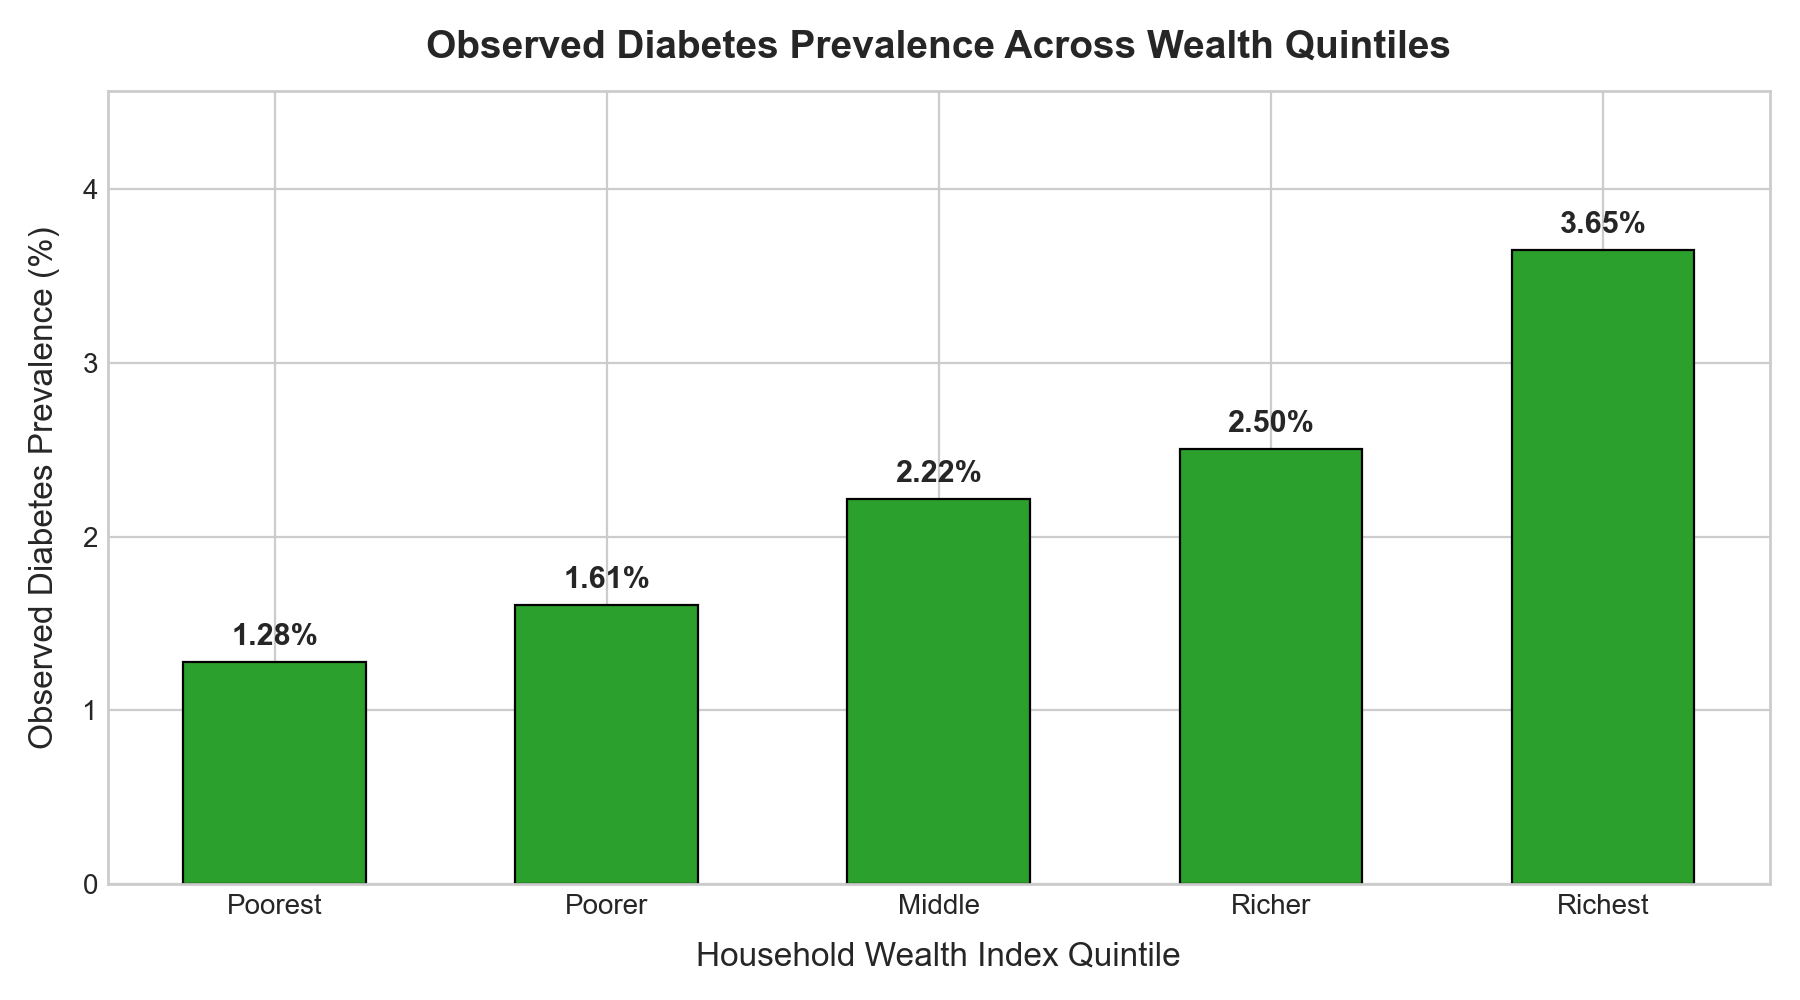

In [6]:
from IPython.display import Image, display
display(Image(filename=str(FIGURES_DIR / "01_target_class_count_plot.png")))
display(Image(filename=str(FIGURES_DIR / "03_age_distribution_by_target.png")))
display(Image(filename=str(FIGURES_DIR / "05_bmi_distribution_by_target.png")))
display(Image(filename=str(FIGURES_DIR / "07_target_status_by_bmi_category.png")))
display(Image(filename=str(FIGURES_DIR / "10_target_status_by_wealth_group.png")))
